# The undercut

**Question:** when a driver pits before the car ahead to gain the position, how often does it work, and how many seconds does it gain on each circuit?

**Data:** all laps from `fct_laps`. The running order and the gap to the car ahead at each lap are rebuilt from the time each driver crosses the line (`lap_started_at`).

In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

DB_PATH = Path("../data/f1.duckdb")
PROCESSED_DIR = Path("../data/processed")
IMAGES_DIR = Path("../images")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

with duckdb.connect(str(DB_PATH), read_only=True) as con:
    laps = con.sql(
        """
        select
            session_key,
            season,
            circuit_name,
            driver_number,
            driver_code,
            team_name,
            lap_number,
            lap_started_at,
            lap_time_s,
            compound,
            tyre_age_laps,
            is_pit_in_lap,
            is_pit_out_lap,
            neutralisation
        from fct_laps
        where lap_started_at is not null
        """
    ).df()

laps = laps.sort_values(["session_key", "lap_number", "lap_started_at"])
by_lap = laps.groupby(["session_key", "lap_number"])
laps["position"] = by_lap.cumcount() + 1
laps["gap_ahead_s"] = by_lap["lap_started_at"].diff().dt.total_seconds()

print(laps.shape)

(99498, 16)


In [2]:
check = laps[
    (laps["season"] == 2025) & (laps["circuit_name"] == "Monza") & (laps["lap_number"] == 30)
]
check[["position", "driver_code", "team_name", "gap_ahead_s", "compound", "tyre_age_laps"]].head(10)

,position,driver_code,team_name,gap_ahead_s,compound,tyre_age_laps
40126,1,VER,Red Bull Racing,NaN,MEDIUM,29
46099,2,NOR,McLaren,6.226,MEDIUM,29
17440,3,PIA,McLaren,6.183,MEDIUM,29
56521,4,LEC,Ferrari,6.580,MEDIUM,29
3140,5,HAM,Ferrari,6.930,MEDIUM,29
46152,6,ALB,Williams,13.307,HARD,29
56574,7,SAI,Williams,2.444,MEDIUM,29
17388,8,OCO,Haas F1 Team,0.812,HARD,29
72060,9,STR,Aston Martin,1.000,HARD,30
33244,10,HAD,Racing Bulls,0.750,HARD,30


## How precise is `lap_started_at`?

OpenF1 describes the lap start time as approximate. Check: for each driver, the time elapsed between the start of two consecutive laps must equal the lap time of the first one.

In [3]:
laps = laps.sort_values(["session_key", "driver_number", "lap_number"])
by_driver = laps.groupby(["session_key", "driver_number"])

elapsed_s = by_driver["lap_started_at"].diff().dt.total_seconds()
previous_lap_time_s = by_driver["lap_time_s"].shift()
consecutive = by_driver["lap_number"].diff() == 1

laps["timing_error_s"] = (elapsed_s - previous_lap_time_s).where(consecutive)

laps["timing_error_s"].abs().describe(percentiles=[0.5, 0.9, 0.99]).round(3)

count    97658.000
mean         0.518
std         28.462
min          0.000
50%          0.047
90%          0.130
99%          0.300
max       4181.990
Name: timing_error_s, dtype: float64

The median error is 0.047 s and 99% of laps are within 0.30 s: precise enough for undercut gains of one second or more. The largest errors are laps interrupted by red flags, where the elapsed time includes the suspension.

## Finding undercut attempts

An undercut attempt is defined as:

1. the **attacker** pits under green flag;
2. at the start of the attacker's in-lap, the attacker is directly behind the **defender**, within 3 seconds;
3. the defender pits under green flag 1 to 3 laps later.

In [4]:
MAX_GAP_S = 3.0
MAX_LAPS_LATER = 3

green_pits = laps.loc[
    laps["is_pit_in_lap"] & laps["neutralisation"].isna(),
    ["session_key", "driver_number", "lap_number"],
]

# 1-2. Attackers: drivers pitting while within MAX_GAP_S of the car ahead.
# Lap 1 is excluded: every driver has the same lap 1 start time, so the
# running order and the gaps at the start of lap 1 are not measurable
attackers = laps.merge(green_pits, on=["session_key", "driver_number", "lap_number"])
attackers = attackers.loc[
    (attackers["lap_number"] > 1)
    & (attackers["position"] > 1)
    & (attackers["gap_ahead_s"] <= MAX_GAP_S),
    [
        "session_key", "season", "circuit_name", "driver_number", "driver_code",
        "lap_number", "position", "gap_ahead_s", "compound", "tyre_age_laps",
    ],
].rename(
    columns={
        "driver_number": "attacker",
        "driver_code": "attacker_code",
        "lap_number": "attacker_pit_lap",
        "gap_ahead_s": "gap_before_s",
        "compound": "attacker_old_compound",
        "tyre_age_laps": "attacker_old_tyre_age",
    }
)

# The car directly ahead of the attacker at that moment: the defender
ahead = laps[["session_key", "lap_number", "position", "driver_number", "driver_code"]].rename(
    columns={
        "lap_number": "attacker_pit_lap",
        "driver_number": "defender",
        "driver_code": "defender_code",
    }
)
ahead["position"] = ahead["position"] + 1
attempts = attackers.merge(ahead, on=["session_key", "attacker_pit_lap", "position"])

# 3. The defender pits 1 to MAX_LAPS_LATER laps later (first such stop)
defender_pits = green_pits.rename(
    columns={"driver_number": "defender", "lap_number": "defender_pit_lap"}
)
attempts = attempts.merge(defender_pits, on=["session_key", "defender"])
attempts = attempts[
    (attempts["defender_pit_lap"] > attempts["attacker_pit_lap"])
    & (attempts["defender_pit_lap"] <= attempts["attacker_pit_lap"] + MAX_LAPS_LATER)
]
attempts = attempts.sort_values("defender_pit_lap").drop_duplicates(
    ["session_key", "attacker", "attacker_pit_lap"]
)

print(f"Undercut attempts: {len(attempts)}")
attempts[
    ["season", "circuit_name", "attacker_code", "defender_code",
     "attacker_pit_lap", "defender_pit_lap", "gap_before_s", "attacker_old_compound"]
].head(10)

Undercut attempts: 234


,season,circuit_name,attacker_code,defender_code,attacker_pit_lap,defender_pit_lap,gap_before_s,attacker_old_compound
239,2023,Zandvoort,ALO,NOR,2,3,0.531,SOFT
305,2023,Zandvoort,OCO,HAM,2,3,0.406,SOFT
620,2024,Melbourne,ALB,MAG,6,7,0.432,HARD
648,2024,Suzuka,HUL,ZHO,5,7,0.698,SOFT
656,2024,Suzuka,BOT,TSU,6,7,0.735,SOFT
614,2024,Melbourne,MAG,BOT,7,8,2.024,HARD
216,2023,Spa-Francorchamps,BOT,SAR,6,8,0.344,SOFT
50,2023,Baku,GAS,SAR,5,8,0.656,MEDIUM
53,2023,Baku,ALB,PIA,7,8,1.719,MEDIUM
672,2024,Imola,GAS,ALB,8,9,0.696,SOFT


## Measuring the outcome

The gap is measured again at the start of lap D+2, where D is the defender's in-lap: by then both drivers have completed their stop and their out-lap.

- **gain**: gap before minus gap after; positive when the attacker closed in;
- **success**: the attacker is ahead after the stops.

Four filters keep only genuine undercuts under normal conditions:

1. dry-to-dry tyre changes only (stops for rain are not undercuts);
2. no safety car, VSC or red flag between the attacker's stop and the measurement;
3. no abnormal stop for either driver (more than 5 s above the race's median pit lane time: penalties, mistakes, repairs);
4. no on-track incident (a gap change of more than 20 s in a few laps cannot come from tyres).

In [5]:
DRY = {"SOFT", "MEDIUM", "HARD"}
SLOW_STOP_MARGIN_S = 5.0
MAX_PLAUSIBLE_GAIN_S = 20.0

after = laps[["session_key", "driver_number", "lap_number", "lap_started_at", "compound"]]

attempts["measure_lap"] = attempts["defender_pit_lap"] + 2
attempts = attempts.merge(
    after.rename(
        columns={
            "driver_number": "attacker",
            "lap_number": "measure_lap",
            "lap_started_at": "attacker_at",
            "compound": "attacker_new_compound",
        }
    ),
    on=["session_key", "attacker", "measure_lap"],
).merge(
    after.rename(
        columns={
            "driver_number": "defender",
            "lap_number": "measure_lap",
            "lap_started_at": "defender_at",
            "compound": "defender_new_compound",
        }
    ),
    on=["session_key", "defender", "measure_lap"],
)

# Keep dry-to-dry tyre changes only: stops for rain are not undercuts
attempts = attempts[
    attempts["attacker_old_compound"].isin(DRY)
    & attempts["attacker_new_compound"].isin(DRY)
    & attempts["defender_new_compound"].isin(DRY)
]

# Drop attempts disturbed by a safety car, VSC or red flag before the measurement
neutralised = set(
    laps.loc[laps["neutralisation"].notna(), ["session_key", "lap_number"]].itertuples(
        index=False, name=None
    )
)
undisturbed = attempts.apply(
    lambda row: all(
        (row["session_key"], lap) not in neutralised
        for lap in range(row["attacker_pit_lap"], row["measure_lap"] + 1)
    ),
    axis=1,
)
attempts = attempts[undisturbed]

# Drop attempts where either driver had an abnormal stop (penalty, mistake,
# repair): more than SLOW_STOP_MARGIN_S above the median pit lane time of the race
with duckdb.connect(str(DB_PATH), read_only=True) as con:
    pit_stops = con.sql(
        "select session_key, driver_number, lap_number, pit_lane_time_s from stg_openf1__pit_stops"
    ).df()

race_median_s = pit_stops.groupby("session_key")["pit_lane_time_s"].transform("median")
slow_stops = pit_stops.loc[
    pit_stops["pit_lane_time_s"] > race_median_s + SLOW_STOP_MARGIN_S,
    ["session_key", "driver_number", "lap_number"],
]
slow = set(slow_stops.itertuples(index=False, name=None))

normal_stops = attempts.apply(
    lambda row: (row["session_key"], row["attacker"], row["attacker_pit_lap"]) not in slow
    and (row["session_key"], row["defender"], row["defender_pit_lap"]) not in slow,
    axis=1,
)
dropped_slow = int((~normal_stops).sum())
attempts = attempts[normal_stops]

attempts["gap_after_s"] = (attempts["attacker_at"] - attempts["defender_at"]).dt.total_seconds()
attempts["gain_s"] = attempts["gap_before_s"] - attempts["gap_after_s"]

# Drop on-track incidents: a gap change of more than MAX_PLAUSIBLE_GAIN_S in a
# few laps cannot come from tyres (damage, loose wheel, failure)
extreme = attempts[attempts["gain_s"].abs() > MAX_PLAUSIBLE_GAIN_S]
attempts = attempts[attempts["gain_s"].abs() <= MAX_PLAUSIBLE_GAIN_S].copy()

attempts["success"] = attempts["gap_after_s"] < 0

print(f"Dropped for an abnormal stop: {dropped_slow}")
print(f"Dropped as on-track incidents: {len(extreme)}")
print(f"Attempts measured: {len(attempts)}")
print(f"Success rate: {attempts['success'].mean():.0%}")
print(f"Median gain: {attempts['gain_s'].median():.2f} s")

Dropped for an abnormal stop: 14
Dropped as on-track incidents: 4
Attempts measured: 184
Success rate: 45%
Median gain: 1.38 s


The four attempts excluded as on-track incidents: in each one a driver lost 30 to 90 seconds in a few laps with normal pit stops, which no tyre difference can explain.

In [6]:
extreme[
    ["season", "circuit_name", "attacker_code", "defender_code",
     "attacker_pit_lap", "defender_pit_lap", "gap_before_s", "gap_after_s", "gain_s"]
].round(1)

,season,circuit_name,attacker_code,defender_code,attacker_pit_lap,defender_pit_lap,gap_before_s,gap_after_s,gain_s
9,2024,Imola,GAS,ALB,8,9,0.7,-88.7,89.4
166,2024,Yas Marina Circuit,MAG,STR,29,32,1.8,31.2,-29.4
180,2023,Montreal,TSU,MAG,34,35,0.4,-44.6,45.0
223,2024,Singapore,RIC,MAG,46,49,1.6,-77.3,79.0


## When does the undercut work?

Success rate and gain by the initial gap to the car ahead.

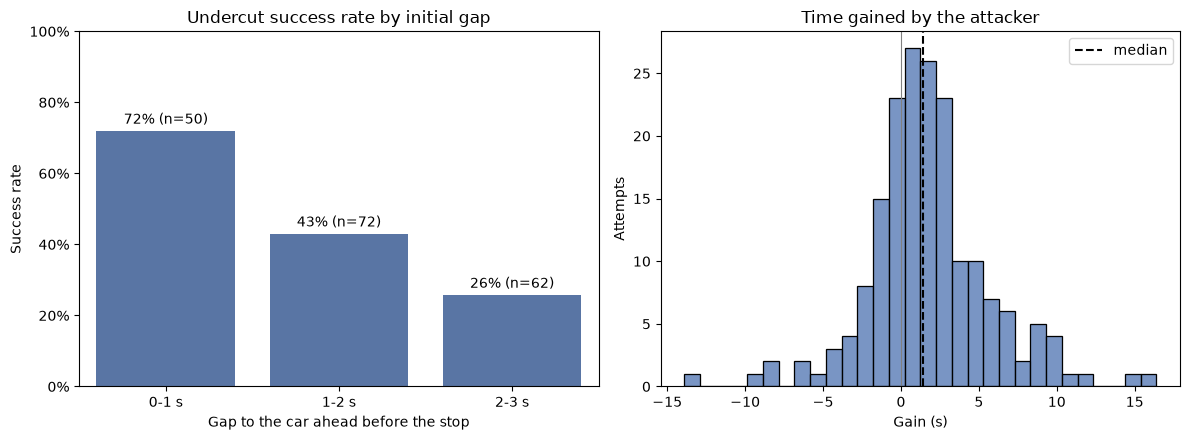

,attempts,success_rate,median_gain_s
gap_band,,,
0-1 s,50,0.72,2.60
1-2 s,72,0.43,0.70
2-3 s,62,0.26,0.88


In [7]:
attempts["gap_band"] = pd.cut(
    attempts["gap_before_s"], bins=[0, 1, 2, 3], labels=["0-1 s", "1-2 s", "2-3 s"]
)

by_gap = attempts.groupby("gap_band", observed=True).agg(
    attempts=("success", "size"),
    success_rate=("success", "mean"),
    median_gain_s=("gain_s", "median"),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(x=by_gap.index, y=by_gap["success_rate"], color="#4C72B0", ax=axes[0])
for i, (rate, n) in enumerate(zip(by_gap["success_rate"], by_gap["attempts"])):
    axes[0].text(i, rate + 0.02, f"{rate:.0%} (n={n})", ha="center")
axes[0].set_ylim(0, 1)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0].set_title("Undercut success rate by initial gap")
axes[0].set_xlabel("Gap to the car ahead before the stop")
axes[0].set_ylabel("Success rate")

sns.histplot(attempts["gain_s"], bins=30, color="#4C72B0", ax=axes[1])
axes[1].axvline(attempts["gain_s"].median(), color="black", linestyle="--", label="median")
axes[1].axvline(0, color="grey", linewidth=0.8)
axes[1].set_title("Time gained by the attacker")
axes[1].set_xlabel("Gain (s)")
axes[1].set_ylabel("Attempts")
axes[1].legend()

fig.tight_layout()
fig.savefig(IMAGES_DIR / "undercut_success_by_gap.png", dpi=150, bbox_inches="tight")
plt.show()

by_gap.round(2)

### Findings

- **184 undercut attempts** in 2023-2026 after excluding stops for rain, attempts disturbed by a neutralisation, abnormal stops (14) and on-track incidents (4).
- **The undercut works in 45% of attempts**, with a median gain of 1.38 s.
- **The initial gap decides**: 72% success within 1 s of the car ahead, 43% between 1 and 2 s, 26% between 2 and 3 s.
- **Close cars gain more** (median 2.6 s within 1 s, against 0.7-0.9 s further back). A likely explanation is dirty air: a car following closely loses grip in the wake of the car ahead, and pitting first also frees it from that.

**Limits.** Gaps are rebuilt from lap start times, precise to about 0.05 s. The 20 s threshold for incidents and the 5 s threshold for abnormal stops are judgement calls. OpenF1 has no pit stop data for the first six races of 2023, so abnormal stops cannot be excluded there. Success is measured two laps after the defender's stop: a position gained can still be lost later.

## Does the undercut gain more where tyres degrade more?

Each attempt is matched with the degradation estimated for its race in `03_tyre_degradation.ipynb` (average over the dry compounds of that race). Races are then split into three equal groups by degradation: low, medium and high.

In [8]:
degradation = pd.read_parquet(PROCESSED_DIR / "tyre_degradation_by_race.parquet")

race_degradation = (
    degradation.groupby("session_key")["degradation_s_per_lap"]
    .mean()
    .rename("race_degradation_s_per_lap")
    .reset_index()
)

with_degradation = attempts.merge(race_degradation, on="session_key", how="inner")
print(f"Attempts with a degradation estimate: {len(with_degradation)} of {len(attempts)}")

with_degradation["degradation_level"] = pd.qcut(
    with_degradation["race_degradation_s_per_lap"], q=3, labels=["Low", "Medium", "High"]
)

by_degradation = with_degradation.groupby("degradation_level", observed=True).agg(
    attempts=("success", "size"),
    min_degradation_s=("race_degradation_s_per_lap", "min"),
    max_degradation_s=("race_degradation_s_per_lap", "max"),
    median_gap_before_s=("gap_before_s", "median"),
    success_rate=("success", "mean"),
    median_gain_s=("gain_s", "median"),
)
by_degradation.round(3)

Attempts with a degradation estimate: 179 of 184


,attempts,min_degradation_s,max_degradation_s,median_gap_before_s,success_rate,median_gain_s
degradation_level,,,,,,
Low,63,-0.013,0.047,1.656,0.270,0.359
Medium,56,0.048,0.075,1.756,0.393,1.261
High,60,0.075,0.187,1.358,0.667,2.452


### Controlling for the initial gap

Attempts in high-degradation races started from smaller gaps, which by itself raises the success rate. Two regressions estimate the effect of degradation and of the initial gap together:

- **gain**: linear regression of the time gained;
- **success**: logistic regression of the probability that the attacker ends up ahead.

Degradation is expressed in hundredths of a second per lap, so each coefficient is the effect of 0.01 s/lap more degradation.

In [9]:
model_data = with_degradation.assign(
    degradation_cs=with_degradation["race_degradation_s_per_lap"] * 100,
    success_int=with_degradation["success"].astype(int),
)

gain_model = smf.ols("gain_s ~ gap_before_s + degradation_cs", data=model_data).fit()
success_model = smf.logit("success_int ~ gap_before_s + degradation_cs", data=model_data).fit(disp=False)

print("Gain (s), linear regression")
print(gain_model.summary().tables[1])
print()
print("Success, logistic regression")
print(success_model.summary().tables[1])

scenarios = pd.DataFrame(
    [(gap, deg) for gap in [0.5, 1.5, 2.5] for deg in [3, 6, 10]],
    columns=["gap_before_s", "degradation_cs"],
)
scenarios["success_probability"] = success_model.predict(scenarios)
scenarios.pivot(
    index="gap_before_s", columns="degradation_cs", values="success_probability"
).round(2)

Gain (s), linear regression
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          1.1997      0.891      1.346      0.180      -0.559       2.958
gap_before_s      -0.6028      0.391     -1.541      0.125      -1.375       0.169
degradation_cs     0.1971      0.071      2.758      0.006       0.056       0.338

Success, logistic regression
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          0.3809      0.489      0.779      0.436      -0.578       1.340
gap_before_s      -1.1066      0.247     -4.475      0.000      -1.591      -0.622
degradation_cs     0.1596      0.044      3.609      0.000       0.073       0.246


degradation_cs,3,6,10
gap_before_s,,,
0.5,0.58,0.69,0.81
1.5,0.31,0.42,0.58
2.5,0.13,0.19,0.31


### Success probability by gap and degradation

The logistic model applied to a grid of initial gaps and degradation levels.

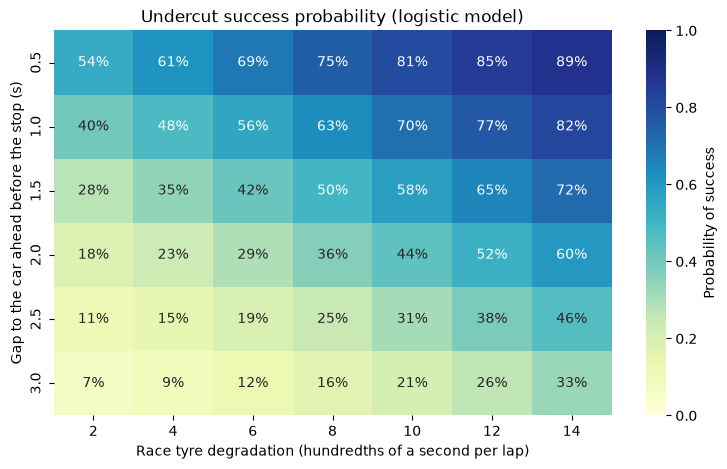

In [10]:
gaps = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
degradations = [2, 4, 6, 8, 10, 12, 14]

grid = pd.DataFrame(
    [(gap, deg) for gap in gaps for deg in degradations],
    columns=["gap_before_s", "degradation_cs"],
)
grid["success_probability"] = success_model.predict(grid)
heat = grid.pivot(index="gap_before_s", columns="degradation_cs", values="success_probability")

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    heat,
    annot=True,
    fmt=".0%",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Probability of success"},
    ax=ax,
)
ax.set_title("Undercut success probability (logistic model)")
ax.set_xlabel("Race tyre degradation (hundredths of a second per lap)")
ax.set_ylabel("Gap to the car ahead before the stop (s)")
fig.savefig(IMAGES_DIR / "undercut_probability_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Findings: degradation and the undercut

- **The undercut gains more where tyres degrade more.** In low-degradation races (up to 0.047 s/lap) it works in 27% of attempts with a median gain of 0.4 s; in medium ones in 39% with 1.3 s; in high ones (above 0.075 s/lap) in 67% with 2.5 s.
- **The effect holds when controlling for the initial gap.** Each extra 0.01 s/lap of degradation adds about 0.20 s of gain (95% CI 0.06-0.34 s). In the logistic model both the initial gap and degradation are significant (p < 0.001).
- **Rule of thumb.** The undercut has at least an even chance when the gap to the car ahead is below about 0.34 + 0.14 × degradation (in hundredths of a second per lap): about 1.2 s on a circuit losing 0.06 s/lap, 1.8 s at 0.10 s/lap, 2.4 s at 0.14 s/lap.

**Limits.** Degradation is the race average over the dry compounds, not the defender's actual tyres. With 179 attempts, the effect of the initial gap on the gain in seconds cannot be distinguished from zero. The logistic model assumes that each variable shifts the log-odds of success linearly.

## Saving the results

The measured attempts and the coefficients of the logistic model are saved to `data/processed` for the Streamlit app.

In [11]:
undercut_columns = [
    "session_key", "season", "circuit_name", "attacker_code", "defender_code",
    "attacker_pit_lap", "defender_pit_lap", "gap_before_s", "gap_after_s",
    "gain_s", "success", "race_degradation_s_per_lap",
]
with_degradation[undercut_columns].to_parquet(
    PROCESSED_DIR / "undercut_attempts.parquet", index=False
)

model_info = {
    "formula": "success ~ gap_before_s + degradation_cs",
    "degradation_unit": "hundredths of a second per lap",
    "n_attempts": int(success_model.nobs),
    "params": success_model.params.to_dict(),
}
(PROCESSED_DIR / "undercut_model.json").write_text(json.dumps(model_info, indent=2))

print(json.dumps(model_info, indent=2))

{
  "formula": "success ~ gap_before_s + degradation_cs",
  "degradation_unit": "hundredths of a second per lap",
  "n_attempts": 179,
  "params": {
    "Intercept": 0.3808618578304595,
    "gap_before_s": -1.1066372671546278,
    "degradation_cs": 0.15955318384444053
  }
}
